# BAB 11 PEMBELAJARAN MENDALAM (Deep Learning 1)
## Praktikum 11.1 Klasifikasi Citra Menggunakan CNN

In [1]:
# ==========================================================
# SETUP GOOGLE COLAB: GPU & AUTO-DOWNLOAD DATASET
# ==========================================================
import os
import tensorflow as tf

# Cek Ketersediaan GPU
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    print(f'>>> [AKTIF] Akselerasi GPU Terdeteksi: {gpus[0].name}')
else:
    print('>>> [INFO] Mode CPU aktif. Untuk GPU: Runtime -> Change runtime type -> T4 GPU.')

# Otomatisasi Unduh & Ekstrak Dataset jika di Colab
if not os.path.exists('Dataset 1') or not os.path.exists('Dataset 2') or not os.path.exists('Dataset 3'):
    print('\n>>> Mengunduh dataset dari server CDN...')
    os.system('wget -q https://files.catbox.moe/po8wfa.zip -O dataset_modul11.zip')
    os.system('unzip -q -o dataset_modul11.zip')
    print('>>> [SUKSES] Dataset 1, Dataset 2, dan Dataset 3 siap digunakan!')


>>> [INFO] Mode CPU aktif. Untuk GPU: Runtime -> Change runtime type -> T4 GPU.


### 2) Import library serta definisikan parameter dan bagi dataset training dan testing:

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from sklearn.metrics import confusion_matrix, classification_report
import tensorflow as tf
import os

# Set seed agar hasil stabil persis dengan modul
tf.random.set_seed(0)
np.random.seed(0)

# PARAMETER
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS = 20
dataset = "Dataset 1/Dataset" if os.path.exists("Dataset 1/Dataset") else "Dataset"

# DATASET
datagen = ImageDataGenerator(rescale=1./255, validation_split=0.3)

train_data = datagen.flow_from_directory(
    dataset,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="binary",
    subset="training",
    shuffle=True,
    seed=0
)

validation_data = datagen.flow_from_directory(
    dataset,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="binary",
    subset="validation",
    shuffle=False,
    seed=0
)

# INFORMASI DATA
total_data = train_data.samples + validation_data.samples
print("====================================")
print("JUMLAH DATA")
print("====================================")
print("Total data :", total_data)
print("Data training :", train_data.samples)
print("Data validasi :", validation_data.samples)
print("Training :", round(train_data.samples/total_data*100, 2), "%")
print("Validasi :", round(validation_data.samples/total_data*100, 2), "%")
print("Class mapping :", train_data.class_indices)

Found 14 images belonging to 2 classes.


Found 6 images belonging to 2 classes.


JUMLAH DATA
Total data : 20
Data training : 14
Data validasi : 6
Training : 70.0 %
Validasi : 30.0 %
Class mapping : {'Mobil': 0, 'Motor': 1}


### 3) Buat model CNN dengan arsitektur sebagai berikut:

In [3]:
# MODEL CNN
model = Sequential([
    Conv2D(32, (3, 3), activation="relu", input_shape=(224, 224, 3)),
    MaxPooling2D(2, 2),
    Conv2D(64, (3, 3), activation="relu"),
    MaxPooling2D(2, 2),
    Conv2D(128, (3, 3), activation="relu"),
    MaxPooling2D(2, 2),
    Flatten(),
    Dense(128, activation="relu"),
    Dropout(0.5),
    Dense(1, activation="sigmoid")
])

# COMPILE
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

C:\Users\LENOVO\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


### 4) Lakukan training model terhadap dataset dan tampilkan grafik akurasi dan loss selama training:

Epoch 1/20


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.3571 - loss: 0.7356

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step - accuracy: 0.3571 - loss: 0.7356 - val_accuracy: 0.5000 - val_loss: 2.8907


Epoch 2/20


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 249ms/step - accuracy: 0.5000 - loss: 2.2072

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 339ms/step - accuracy: 0.5000 - loss: 2.2072 - val_accuracy: 0.5000 - val_loss: 1.3857


... (50 outputs left out)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 348ms/step - accuracy: 1.0000 - loss: 0.0043 - val_accuracy: 0.8333 - val_loss: 0.8149


Epoch 20/20


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 287ms/step - accuracy: 1.0000 - loss: 0.0042

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 374ms/step - accuracy: 1.0000 - loss: 0.0042 - val_accuracy: 0.6667 - val_loss: 1.2520


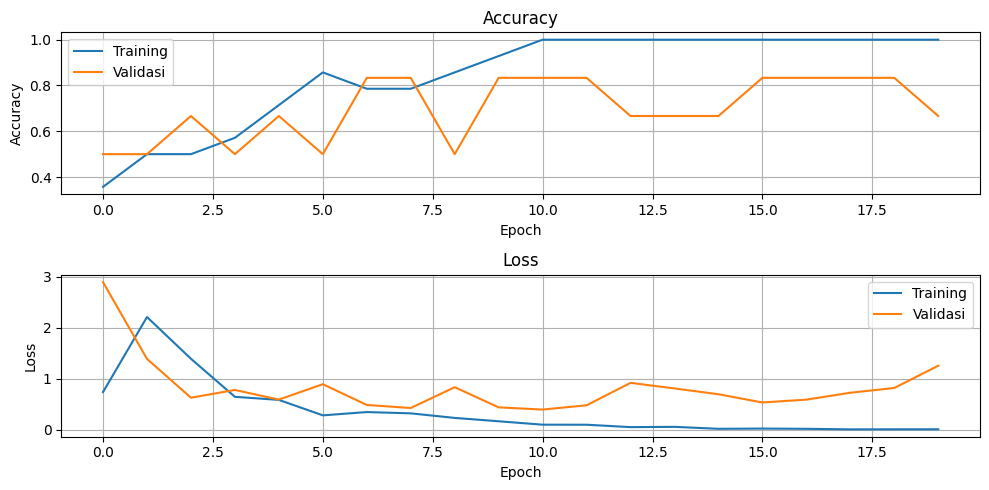

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step - accuracy: 0.6667 - loss: 1.2520

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step - accuracy: 0.6667 - loss: 1.2520


HASIL VALIDASI
Validation Loss : 1.252
Validation Accuracy : 66.67 %


In [4]:
# TRAINING
history = model.fit(
    train_data,
    validation_data=validation_data,
    epochs=EPOCHS
)

# GRAFIK ACCURACY DAN LOSS
plt.figure(figsize=(10, 5))
plt.subplot(2, 1, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validasi")
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()

plt.subplot(2, 1, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validasi")
plt.title("Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

# EVALUASI
loss, accuracy = model.evaluate(validation_data)
print("====================================")
print("HASIL VALIDASI")
print("====================================")
print("Validation Loss :", round(loss, 4))
print("Validation Accuracy :", round(accuracy*100, 2), "%")

### 5) Lakukan validasi dari model yang telah di-training dan simpan model:

In [5]:
# PREDIKSI VALIDASI
validation_data.reset()
hasil = model.predict(validation_data)
y_pred = (hasil >= 0.5).astype(int).reshape(-1)
y_true = validation_data.classes

# CONFUSION MATRIX
cm = confusion_matrix(y_true, y_pred)
print("====================================")
print("CONFUSION MATRIX")
print("====================================")
print(cm)

# CLASSIFICATION REPORT
nama_kelas = list(validation_data.class_indices.keys())
print("====================================")
print("CLASSIFICATION REPORT")
print("====================================")
print(classification_report(y_true, y_pred, target_names=nama_kelas))

# SIMPAN MODEL
model.save("model_motor_mobil.keras")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 117ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 122ms/step


CONFUSION MATRIX
[[3 0]
 [2 1]]
CLASSIFICATION REPORT
              precision    recall  f1-score   support

       Mobil       0.60      1.00      0.75         3
       Motor       1.00      0.33      0.50         3

    accuracy                           0.67         6
   macro avg       0.80      0.67      0.62         6
weighted avg       0.80      0.67      0.62         6

